# Default-parameter study analysis

Visualize the CSV output from [`default_parameter_study.jl`](./default_parameter_study.jl). By default, this notebook selects the newest `default_parameters_*` directory and reloads whatever data is currently available, so it can be used while a study is still running. Set `STUDY_DIR` in the next cell to a specific run directory if needed.

The blocking estimates group adjacent sweep energies and compare the resulting SEM and integrated autocorrelation estimate as the block length increases. The autocorrelation run uses the initial wavefunction parameters (`kappa = 1` or zero Jastrow coefficients), not an optimized wavefunction. Interpret conclusions accordingly.

In [131]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "VMCBoseHubbard" / "examples" / "default_parameter_study.jl").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Could not locate the repository root containing VMCBoseHubbard/examples/default_parameter_study.jl")
DATA_DIR = REPO_ROOT / "VMCBoseHubbard" / "data" / "studies"

# Set to a specific output directory, e.g.
# STUDY_DIR = DATA_DIR / "default_parameters_20261010_194500"
STUDY_DIR = None

if STUDY_DIR is None:
    candidates = sorted(
        DATA_DIR.glob("default_parameters_*"),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    ) if DATA_DIR.is_dir() else []
    STUDY_DIR = candidates[0] if candidates else None
else:
    STUDY_DIR = Path(STUDY_DIR).expanduser()

if STUDY_DIR is None:
    print(f"No study output directory found under {DATA_DIR}. Start the study, then rerun this cell.")
else:
    print(f"Study directory: {STUDY_DIR.resolve()}")

Study directory: /Users/wmallah/Documents/GitHub/Bose_Hubbard_VMC/VMCBoseHubbard/data/studies/default_parameters_20261010_205120


In [132]:
def load_study_csv(filename):
    """Load a study CSV if present; tolerate incomplete trailing rows during a run."""
    if STUDY_DIR is None:
        return pd.DataFrame()
    path = STUDY_DIR / filename
    if not path.is_file():
        print(f"Waiting for {path.name} to be created.")
        return pd.DataFrame()
    try:
        frame = pd.read_csv(path, on_bad_lines="skip")
    except pd.errors.EmptyDataError:
        print(f"{path.name} exists but has no complete CSV header yet.")
        return pd.DataFrame()
    if frame.empty:
        print(f"{path.name} has no complete data rows yet.")
    return frame


timeseries = load_study_csv("autocorrelation_timeseries.csv")
blocking = load_study_csv("autocorrelation_blocking.csv")
updates = load_study_csv("sr_update_history.csv")

if not updates.empty and "eta_decay" not in updates:
    # Earlier study output used the optimizer's original fixed 0.998 decay.
    updates["eta_decay"] = 0.998
    updates["learning_rate"] = updates["eta_initial"] * 0.998 ** (updates["iteration"] - 1)

for frame, columns in [
    (timeseries, {"trial_state", "U_over_t", "sweep", "energy"}),
    (blocking, {"trial_state", "U_over_t", "block_sweeps", "sem_energy", "tau_int_sweeps"}),
    (updates, {"trial_state", "U_over_t", "eta_initial", "eta_decay", "iteration", "learning_rate", "energy", "update_rms", "gradient_norm"}),
]:
    missing = columns - set(frame.columns)
    if not frame.empty and missing:
        raise ValueError(f"Study CSV is missing expected columns: {sorted(missing)}")

print(f"Loaded {len(timeseries):,} energy sweeps, {len(blocking):,} blocking rows, "
      f"and {len(updates):,} SR update rows.")

Waiting for autocorrelation_timeseries.csv to be created.
Waiting for autocorrelation_blocking.csv to be created.
Loaded 0 energy sweeps, 0 blocking rows, and 2,270 SR update rows.


## Energy autocorrelation

Each time-series point is the mean energy across walkers for one Monte Carlo sweep. The blocking curves include larger blocks only while at least 16 blocks remain, as emitted by the study runner. A stable SEM / autocorrelation estimate across successive block sizes is evidence that blocks are long enough; it is not a guarantee that all slow modes have equilibrated.

In [133]:
def study_groups(frame):
    if frame.empty:
        return []
    return list(frame.groupby(["trial_state", "U_over_t"], sort=True))


groups = study_groups(timeseries)
if groups:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for ax, ((state, interaction), data) in zip(axes.flat, groups):
        data = data.sort_values("sweep")
        stride = max(1, len(data) // 20_000)
        plotted = data.iloc[::stride]
        ax.plot(plotted["sweep"], plotted["energy"], linewidth=0.8)
        ax.set(title=f"{state}, U/t={interaction:g}", xlabel="Sweep", ylabel="Energy per sweep")
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    fig.suptitle("Energy time series after equilibration")
    plt.show()

else:
    print("No complete energy time-series data available yet.")

No complete energy time-series data available yet.


In [134]:
groups = study_groups(blocking)
if groups:
    fig_sem, axes_sem = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    fig_tau, axes_tau = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for ax_sem, ax_tau, ((state, interaction), data) in zip(axes_sem.flat, axes_tau.flat, groups):
        data = data.sort_values("block_sweeps")
        ax_sem.plot(data["block_sweeps"], data["sem_energy"], marker="o")
        ax_sem.set(title=f"{state}, U/t={interaction:g}", xlabel="Block size (sweeps)", ylabel="Energy SEM")
        ax_sem.set_xscale("log", base=2)
        ax_tau.plot(data["block_sweeps"], data["tau_int_sweeps"], marker="o")
        ax_tau.set(title=f"{state}, U/t={interaction:g}", xlabel="Block size (sweeps)", ylabel="Integrated autocorrelation (sweeps)")
        ax_tau.set_xscale("log", base=2)
    for axes in (axes_sem, axes_tau):
        for ax in axes.flat[len(groups):]:
            ax.set_visible(False)
    fig_sem.suptitle("Blocking analysis: energy uncertainty")
    fig_tau.suptitle("Blocking analysis: integrated autocorrelation estimate")
    plt.show()

else:
    print("No complete blocking data available yet.")

No complete blocking data available yet.


## Stochastic Reconfiguration updates

Each panel compares the tested initial learning rates and multiplicative decay factors for one trial state and interaction. Energy and gradient norm show optimization progress; the applied RMS step shows the actual parameter update magnitude (including projection/clipping behavior from the optimizer). Partial histories are plotted as-is, so rerun the loading and plotting cells to refresh them during a long run.

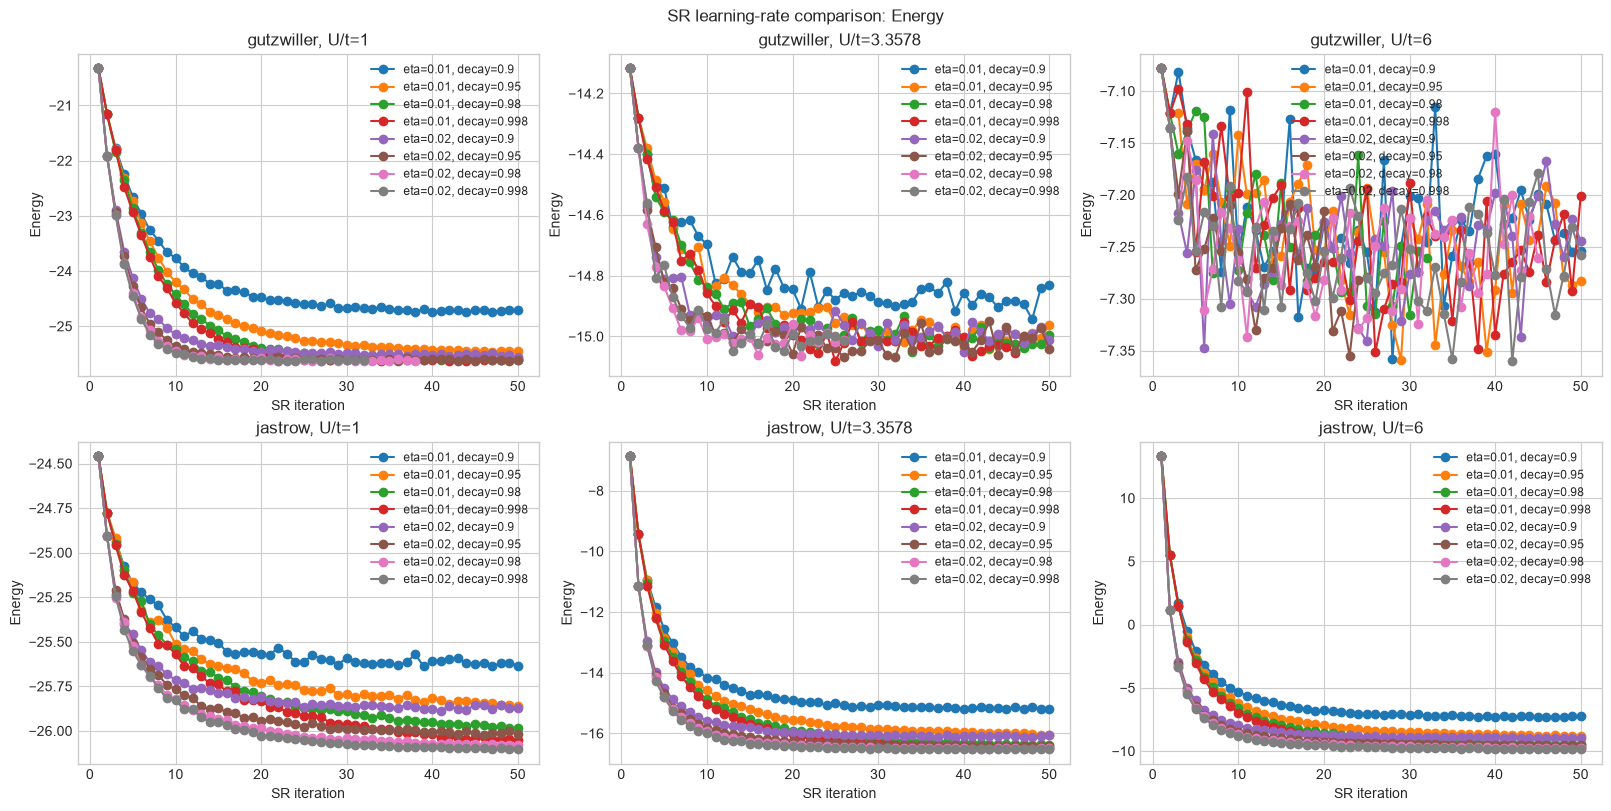

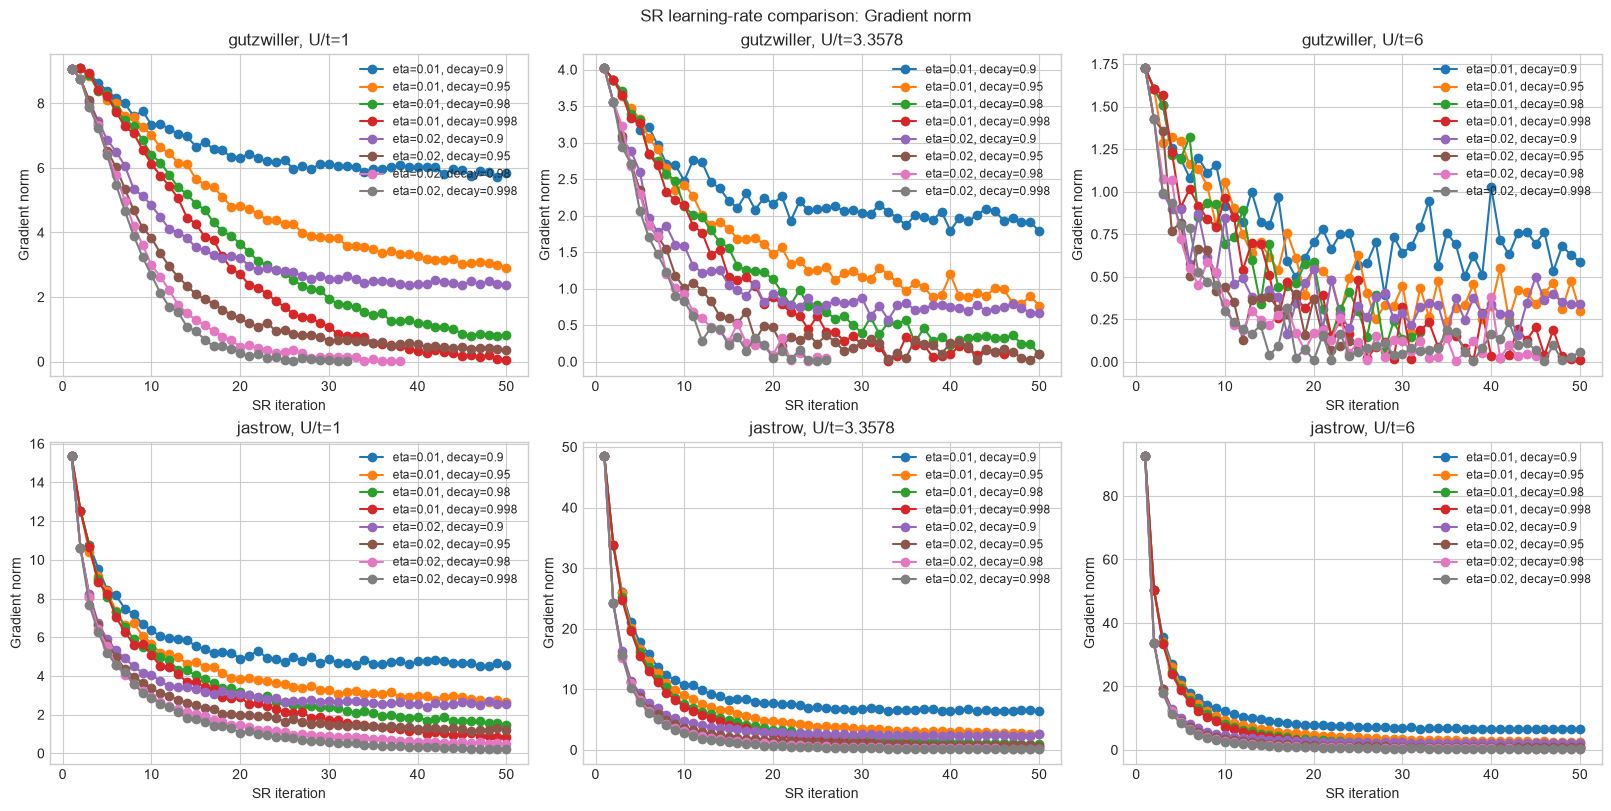

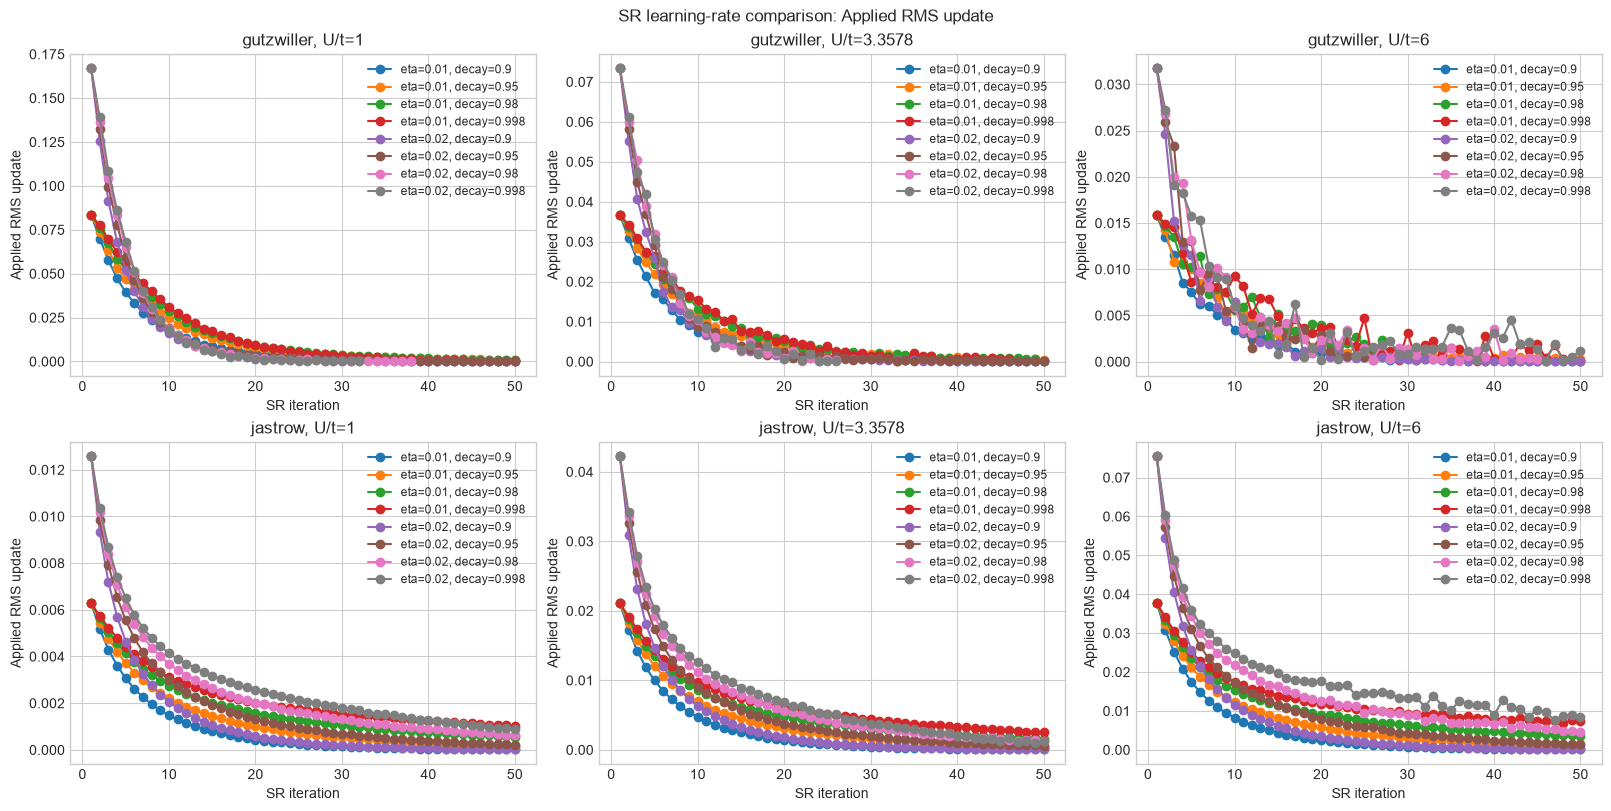

,trial_state,U_over_t,eta_initial,eta_decay,iterations,final_energy,final_energy_sem,final_update_rms,final_gradient_norm
0,gutzwiller,1.0000,0.01,0.900,50,-24.699118,0.018174,0.000166,5.842494
1,gutzwiller,1.0000,0.01,0.950,50,-25.447393,0.017964,0.000859,2.913506
2,gutzwiller,1.0000,0.01,0.980,50,-25.620684,0.013445,0.000970,0.838386
3,gutzwiller,1.0000,0.01,0.998,50,-25.601636,0.011941,0.000169,0.062596
4,gutzwiller,1.0000,0.02,0.900,50,-25.553231,0.009917,0.000096,2.384217
5,gutzwiller,1.0000,0.02,0.950,50,-25.619786,0.007478,0.000171,0.350932
6,gutzwiller,1.0000,0.02,0.980,38,-25.623883,0.009816,0.000014,0.005097
7,gutzwiller,1.0000,0.02,0.998,32,-25.617237,0.011675,0.000080,0.014912
8,gutzwiller,3.3578,0.01,0.900,50,-14.831430,0.030190,0.000075,1.784768
9,gutzwiller,3.3578,0.01,0.950,50,-14.962604,0.032176,0.000414,0.768226


In [135]:
groups = study_groups(updates)
if groups:
    metrics = [
        ("energy", "Energy"),
        ("gradient_norm", "Gradient norm"),
        ("update_rms", "Applied RMS update"),
    ]
    for metric, ylabel in metrics:
        fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
        for ax, ((state, interaction), data) in zip(axes.flat, groups):
            for (eta, decay), run in data.groupby(["eta_initial", "eta_decay"], sort=True):
                run = run.sort_values("iteration")
                ax.plot(run["iteration"], run[metric], marker="o", label=f"eta={eta:g}, decay={decay:g}")
            ax.set(title=f"{state}, U/t={interaction:g}", xlabel="SR iteration", ylabel=ylabel)
            ax.legend(fontsize="small")
        for ax in axes.flat[len(groups):]:
            ax.set_visible(False)
        fig.suptitle(f"SR learning-rate comparison: {ylabel}")
        plt.show()

    summary = (
        updates.sort_values("iteration")
        .groupby(["trial_state", "U_over_t", "eta_initial", "eta_decay"], as_index=False)
        .agg(iterations=("iteration", "max"),
             final_energy=("energy", "last"),
             final_energy_sem=("sem_energy", "last"),
             final_update_rms=("update_rms", "last"),
             final_gradient_norm=("gradient_norm", "last"))
    )
    display(summary)

else:
    print("No complete SR update history available yet.")